In [ ]:
"""
04_hypothesis_validation.ipynb
Phase 5: Hypothesis Testing
Date: 2026-08-28
Description: Statistical validation of all research hypotheses
"""

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sys
import warnings
warnings.filterwarnings('ignore')

# Statistical libraries
from scipy import stats
from scipy.stats import mannwhitneyu, wilcoxon, shapiro, levene
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.tsa.stattools import grangercausalitytests
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# Set up plotting style
sns.set_theme(style='whitegrid')
sns.set_palette("Set2")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12

# Add src to path
sys.path.append(str(Path.cwd().parent / 'src'))
from config import DATA_PROCESSED, RESULTS_FIGURES, RESULTS_TABLES, ALPHA, RANDOM_SEED

# Set seed
np.random.seed(RANDOM_SEED)

print(" All imports loaded successfully!")
print(f"Significance level (α): {ALPHA}")
print(f"Random seed: {RANDOM_SEED}")

 All imports loaded successfully!
Significance level (α): 0.05
Random seed: 42


In [49]:
# Load data with features
print("Loading feature-engineered data...")

reddit_df = pd.read_parquet(DATA_PROCESSED / 'reddit_with_features.parquet')
x_df = pd.read_parquet(DATA_PROCESSED / 'twitter_with_features.parquet')
combined_df = pd.read_parquet(DATA_PROCESSED / 'combined_with_features.parquet')

print(f" Reddit data: {len(reddit_df):,} rows")
print(f" X data: {len(x_df):,} rows")
print(f" Combined data: {len(combined_df):,} rows")

# Prepare platform-specific dataframes for testing
reddit_values = {col: reddit_df[col].dropna() for col in reddit_df.columns}
x_values = {col: x_df[col].dropna() for col in x_df.columns}

print("\n Data ready for hypothesis testing")

Loading feature-engineered data...
 Reddit data: 9,000 rows
 X data: 9,000 rows
 Combined data: 18,000 rows

 Data ready for hypothesis testing


In [50]:
"""
HELPER FUNCTIONS FOR HYPOTHESIS TESTING
"""

def test_normality(data, name):
    """Test for normality using Shapiro-Wilk test."""
    data = data.dropna()
    if len(data) < 3:
        return {'statistic': np.nan, 'p_value': np.nan, 'is_normal': False, 'sample_size': len(data)}
    if len(data) > 5000:
        sample = data.sample(5000, random_state=RANDOM_SEED)
    else:
        sample = data

    stat, p = shapiro(sample)
    return {'statistic': stat, 'p_value': p, 'is_normal': p > 0.05, 'sample_size': len(sample)}

def test_variance_homogeneity(data1, data2):
    """Test for equal variances using Levene's test."""
    data1 = data1.dropna()
    data2 = data2.dropna()
    if len(data1) < 2 or len(data2) < 2:
        return {'statistic': np.nan, 'p_value': np.nan, 'equal_variances': False}
    stat, p = levene(data1, data2)
    return {'statistic': stat, 'p_value': p, 'equal_variances': p > 0.05}

def mann_whitney_test(data1, data2, alternative='two-sided', name1='Group1', name2='Group2'):
    """Perform Mann-Whitney U test with effect size."""
    data1 = data1.dropna()
    data2 = data2.dropna()
    n1, n2 = len(data1), len(data2)
    if n1 == 0 or n2 == 0:
        return {
            'test': 'Mann-Whitney U',
            'statistic': np.nan,
            'p_value': np.nan,
            'significant': False,
            'cliff_delta': np.nan,
            'effect_size': 'not estimable',
            'n1': n1,
            'n2': n2,
            'mean1': data1.mean() if n1 else np.nan,
            'mean2': data2.mean() if n2 else np.nan,
            'median1': data1.median() if n1 else np.nan,
            'median2': data2.median() if n2 else np.nan,
            'name1': name1,
            'name2': name2
        }

    stat, p = mannwhitneyu(data1, data2, alternative=alternative)
    cliff_delta = (2 * stat / (n1 * n2)) - 1

    if abs(cliff_delta) < 0.147:
        effect_size = 'negligible'
    elif abs(cliff_delta) < 0.33:
        effect_size = 'small'
    elif abs(cliff_delta) < 0.474:
        effect_size = 'medium'
    else:
        effect_size = 'large'

    return {
        'test': 'Mann-Whitney U',
        'statistic': stat,
        'p_value': p,
        'significant': p < ALPHA,
        'cliff_delta': cliff_delta,
        'effect_size': effect_size,
        'n1': n1,
        'n2': n2,
        'mean1': data1.mean(),
        'mean2': data2.mean(),
        'median1': data1.median(),
        'median2': data2.median(),
        'name1': name1,
        'name2': name2
    }

def interpret_results(result, hypothesis):
    """Print interpretation of test results."""
    print(f"\n=== {hypothesis} ===")
    print(f"Test: {result['test']}")
    print(f"U-statistic: {result['statistic']:.3f}")
    print(f"p-value: {result['p_value']:.4f}")
    print(f"Significant: {'YES' if result['significant'] else 'NO'} (p {'<' if result['significant'] else '>'} {ALPHA})")
    print(f"Effect Size (Cliff's Delta): {result['cliff_delta']:.3f} ({result['effect_size']})")
    print(f"\nGroup 1 ({result.get('name1', 'Group1')}): mean={result['mean1']:.3f}, median={result['median1']:.3f}, n={result['n1']}")
    print(f"Group 2 ({result.get('name2', 'Group2')}): mean={result['mean2']:.3f}, median={result['median2']:.3f}, n={result['n2']}")

    if result['significant']:
        direction = "higher" if result['mean1'] > result['mean2'] else "lower"
        print(f"\nHypothesis SUPPORTED: Group 1 has {direction} values than Group 2")
    else:
        print("\nHypothesis NOT SUPPORTED: No significant difference detected")

    return result

H1: LEXICAL COMPLEXITY

Testing normality...
Reddit FK Grade: p=0.0000 (non-normal)
X FK Grade: p=0.0000 (non-normal)

Testing variance homogeneity...
Levene's test: p=0.0000 (unequal variances)

Performing Mann-Whitney U test...

=== H1: Lexical Complexity (Flesch-Kincaid Grade) ===
Test: Mann-Whitney U
U-statistic: 26973223.500
p-value: 0.0000
Significant: YES (p < 0.05)
Effect Size (Cliff's Delta): -0.334 (medium)

Group 1 (Reddit): mean=8.466, median=7.851, n=9000
Group 2 (X): mean=10.804, median=10.138, n=9000

Hypothesis SUPPORTED: Group 1 has lower values than Group 2

--------------------------------------------------
Additional test: TTR (Type-Token Ratio)

=== H1b: Lexical Diversity (TTR) ===
Test: Mann-Whitney U
U-statistic: 37084483.500
p-value: 0.0000
Significant: YES (p < 0.05)
Effect Size (Cliff's Delta): -0.084 (negligible)

Group 1 (Reddit): mean=0.864, median=0.878, n=9000
Group 2 (X): mean=0.881, median=0.894, n=9000

Hypothesis SUPPORTED: Group 1 has lower values th

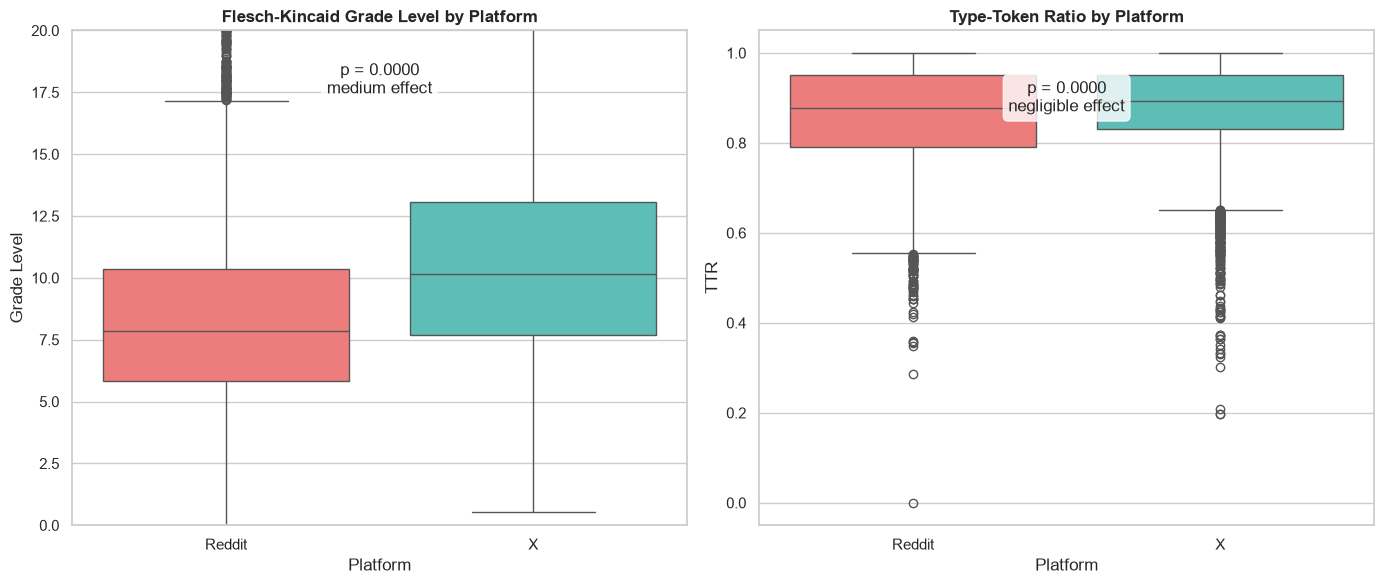


 H1 visualization saved


In [51]:
"""
HYPOTHESIS 1: LEXICAL COMPLEXITY
H1: Reddit comments will exhibit significantly higher lexical complexity than X replies
"""

print("=" * 70)
print("H1: LEXICAL COMPLEXITY")
print("=" * 70)

# Test normality
print("\nTesting normality...")
normality_fk_reddit = test_normality(reddit_df['fk_grade'], 'Reddit FK Grade')
normality_fk_x = test_normality(x_df['fk_grade'], 'X FK Grade')
print(f"Reddit FK Grade: p={normality_fk_reddit['p_value']:.4f} {'(normal)' if normality_fk_reddit['is_normal'] else '(non-normal)'}")
print(f"X FK Grade: p={normality_fk_x['p_value']:.4f} {'(normal)' if normality_fk_x['is_normal'] else '(non-normal)'}")

# Test variance homogeneity
print("\nTesting variance homogeneity...")
variance_test = test_variance_homogeneity(reddit_df['fk_grade'], x_df['fk_grade'])
print(f"Levene's test: p={variance_test['p_value']:.4f} {'(equal variances)' if variance_test['equal_variances'] else '(unequal variances)'}")

# Perform Mann-Whitney U test (non-parametric, robust to non-normality)
print("\nPerforming Mann-Whitney U test...")
result_h1 = mann_whitney_test(
    reddit_df['fk_grade'], 
    x_df['fk_grade'],
    alternative='two-sided',
    name1='Reddit',
    name2='X'
)
result_h1 = interpret_results(result_h1, "H1: Lexical Complexity (Flesch-Kincaid Grade)")

# Also test TTR
print("\n" + "-" * 50)
print("Additional test: TTR (Type-Token Ratio)")
result_ttr = mann_whitney_test(
    reddit_df['ttr'], 
    x_df['ttr'],
    alternative='two-sided',
    name1='Reddit',
    name2='X'
)
result_ttr = interpret_results(result_ttr, "H1b: Lexical Diversity (TTR)")

# Store results
hypothesis_results = {'H1': result_h1, 'H1b': result_ttr}

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Boxplot for FK Grade
ax = axes[0]
sns.boxplot(data=combined_df, x='platform', y='fk_grade', ax=ax, palette=['#FF6B6B', '#4ECDC4'])
ax.set_title('Flesch-Kincaid Grade Level by Platform', fontweight='bold')
ax.set_xlabel('Platform')
ax.set_ylabel('Grade Level')
ax.set_ylim(0, 20)

# Add p-value annotation
ax.text(0.5, 18, f"p = {result_h1['p_value']:.4f}\n{result_h1['effect_size']} effect", 
        ha='center', va='center', fontsize=12, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Boxplot for TTR
ax = axes[1]
sns.boxplot(data=combined_df, x='platform', y='ttr', ax=ax, palette=['#FF6B6B', '#4ECDC4'])
ax.set_title('Type-Token Ratio by Platform', fontweight='bold')
ax.set_xlabel('Platform')
ax.set_ylabel('TTR')

# Add p-value annotation
ax.text(0.5, 0.9, f"p = {result_ttr['p_value']:.4f}\n{result_ttr['effect_size']} effect", 
        ha='center', va='center', fontsize=12, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.savefig(RESULTS_FIGURES / 'hypothesis_h1_lexical_complexity.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n H1 visualization saved")

In [52]:
# Additional test: MTLD (length-robust lexical diversity)
print("\n" + "-" * 50)
print("Additional test: MTLD (Measure of Textual Lexical Diversity)")
result_mtld = mann_whitney_test(
    reddit_df['mtld'],
    x_df['mtld'],
    alternative='two-sided',
    name1='Reddit',
    name2='X'
)
result_mtld = interpret_results(result_mtld, "H1c: Lexical Diversity (MTLD)")

# Additional test: lexical sophistication (word-rarity via frequency norms)
print("\n" + "-" * 50)
print("Additional test: Lexical Sophistication (word rarity)")
result_soph = mann_whitney_test(
    reddit_df['lexical_sophistication'],
    x_df['lexical_sophistication'],
    alternative='two-sided',
    name1='Reddit',
    name2='X'
)
result_soph = interpret_results(result_soph, "H1d: Lexical Sophistication")

# Store results
hypothesis_results = {'H1': result_h1, 'H1b': result_ttr, 'H1c': result_mtld, 'H1d': result_soph}


--------------------------------------------------
Additional test: MTLD (Measure of Textual Lexical Diversity)

=== H1c: Lexical Diversity (MTLD) ===
Test: Mann-Whitney U
U-statistic: 39201470.500
p-value: 0.0002
Significant: YES (p < 0.05)
Effect Size (Cliff's Delta): -0.032 (negligible)

Group 1 (Reddit): mean=72.990, median=68.040, n=9000
Group 2 (X): mean=79.679, median=67.760, n=9000

Hypothesis SUPPORTED: Group 1 has lower values than Group 2

--------------------------------------------------
Additional test: Lexical Sophistication (word rarity)

=== H1d: Lexical Sophistication ===
Test: Mann-Whitney U
U-statistic: 21123762.500
p-value: 0.0000
Significant: YES (p < 0.05)
Effect Size (Cliff's Delta): -0.478 (large)

Group 1 (Reddit): mean=1.268, median=1.227, n=9000
Group 2 (X): mean=1.588, median=1.487, n=9000

Hypothesis SUPPORTED: Group 1 has lower values than Group 2



H2: EVIDENTIARY RIGOR

Testing normality...
Reddit Rigor: p=0.0000 (non-normal)
X Rigor: p=0.0000 (non-normal)

Performing Mann-Whitney U test for Rigor Score...

=== H2: Evidentiary Rigor Score ===
Test: Mann-Whitney U
U-statistic: 49726754.000
p-value: 0.0000
Significant: YES (p < 0.05)
Effect Size (Cliff's Delta): 0.228 (small)

Group 1 (Reddit): mean=0.031, median=0.005, n=9000
Group 2 (X): mean=0.006, median=0.000, n=9000

Hypothesis SUPPORTED: Group 1 has higher values than Group 2

--------------------------------------------------
Additional test: Link Rate (has_link binary)
Reddit link rate: 5.3%
X link rate: 0.0%
Chi-square test: p=0.0000 (significant)


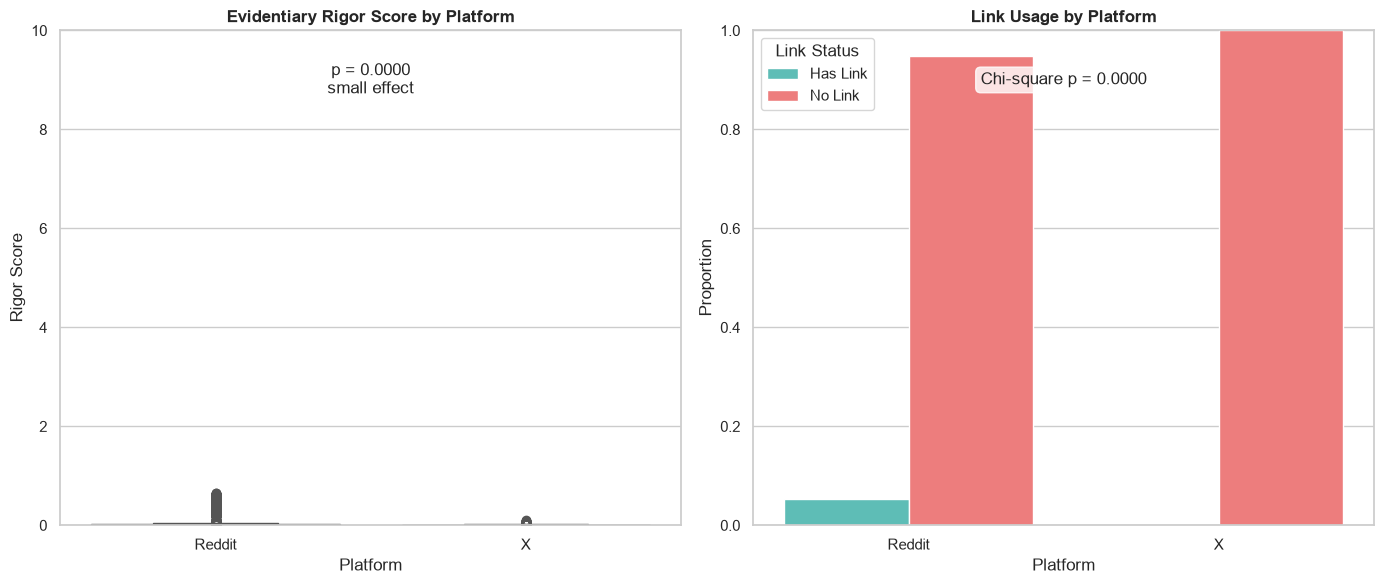


 H2 visualization saved


In [ ]:
"""
HYPOTHESIS 2: EVIDENTIARY RIGOR
H2: Reddit comments will contain a higher density of high-credibility hyperlinks than X replies
"""

print("\n" + "=" * 70)
print("H2: EVIDENTIARY RIGOR")
print("=" * 70)

# Test normality
print("\nTesting normality...")
normality_rigor_reddit = test_normality(reddit_df['rigor_score'], 'Reddit Rigor')
normality_rigor_x = test_normality(x_df['rigor_score'], 'X Rigor')
print(f"Reddit Rigor: p={normality_rigor_reddit['p_value']:.4f} {'(normal)' if normality_rigor_reddit['is_normal'] else '(non-normal)'}")
print(f"X Rigor: p={normality_rigor_x['p_value']:.4f} {'(normal)' if normality_rigor_x['is_normal'] else '(non-normal)'}")

# Perform Mann-Whitney U test for Rigor Score
print("\nPerforming Mann-Whitney U test for Rigor Score...")
result_h2 = mann_whitney_test(
    reddit_df['rigor_score'], 
    x_df['rigor_score'],
    alternative='two-sided',
    name1='Reddit',
    name2='X'
)
result_h2 = interpret_results(result_h2, "H2: Evidentiary Rigor Score")

# Also test link rate
print("\n" + "-" * 50)
print("Additional test: Link Rate (has_link binary)")
reddit_link_rate = reddit_df['has_link'].mean()
x_link_rate = x_df['has_link'].mean()
link_table = [
    [reddit_df['has_link'].sum(), len(reddit_df) - reddit_df['has_link'].sum()],
    [x_df['has_link'].sum(), len(x_df) - x_df['has_link'].sum()]
]
if len(reddit_df) == 0 or len(x_df) == 0 or any(sum(row) == 0 for row in link_table) or any(sum(column) == 0 for column in zip(*link_table)):
    chi2_stat, chi2_p = np.nan, np.nan
else:
    chi2_stat, chi2_p = stats.chi2_contingency(link_table)[:2]

print(f"Reddit link rate: {reddit_link_rate*100:.1f}%")
print(f"X link rate: {x_link_rate*100:.1f}%")
print(f"Chi-square test: p={chi2_p:.4f} {'(significant)' if pd.notna(chi2_p) and chi2_p < ALPHA else '(not estimable or not significant)'}")

# Store results
hypothesis_results['H2'] = result_h2
hypothesis_results['H2_link_rate'] = {
    'test': 'Chi-square',
    'statistic': chi2_stat,
    'p_value': chi2_p,
    'significant': bool(pd.notna(chi2_p) and chi2_p < ALPHA),
    'reddit_rate': reddit_link_rate,
    'x_rate': x_link_rate
}

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Boxplot for Rigor Score
ax = axes[0]
sns.boxplot(data=combined_df, x='platform', y='rigor_score', ax=ax, palette=['#FF6B6B', '#4ECDC4'])
ax.set_title('Evidentiary Rigor Score by Platform', fontweight='bold')
ax.set_xlabel('Platform')
ax.set_ylabel('Rigor Score')
ax.set_ylim(0, 10)

# Add p-value annotation
ax.text(0.5, 9, f"p = {result_h2['p_value']:.4f}\n{result_h2['effect_size']} effect", 
        ha='center', va='center', fontsize=12, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Bar plot for Link Rate
ax = axes[1]
link_rates = pd.DataFrame({
    'Platform': ['Reddit', 'X'],
    'Has Link': [reddit_link_rate, x_link_rate],
    'No Link': [1 - reddit_link_rate, 1 - x_link_rate]
})
link_rates_melted = link_rates.melt(id_vars=['Platform'], var_name='Link Status', value_name='Proportion')
sns.barplot(data=link_rates_melted, x='Platform', y='Proportion', hue='Link Status', ax=ax, palette=['#4ECDC4', '#FF6B6B'])
ax.set_title('Link Usage by Platform', fontweight='bold')
ax.set_ylabel('Proportion')
ax.set_ylim(0, 1)

# Add p-value annotation
ax.text(0.5, 0.9, f"Chi-square p = {chi2_p:.4f}", 
        ha='center', va='center', fontsize=12, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.savefig(RESULTS_FIGURES / 'hypothesis_h2_evidentiary_rigor.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n H2 visualization saved")


H3: TEMPORAL SENTIMENT PATTERNS
Reddit peak sentiment at hour 227: 0.862
X peak sentiment at hour 349: 0.488
Average sentiment volatility (std): Reddit=0.561, X=0.544
Reddit decay slope: 0.0001 (negative = decay)
X decay slope: -0.0000 (negative = decay)

Testing peak timing difference...
Peak hour difference (X - Reddit): 200.7 hours
95% CI: [-95.1, 453.0]
X peaks later than Reddit


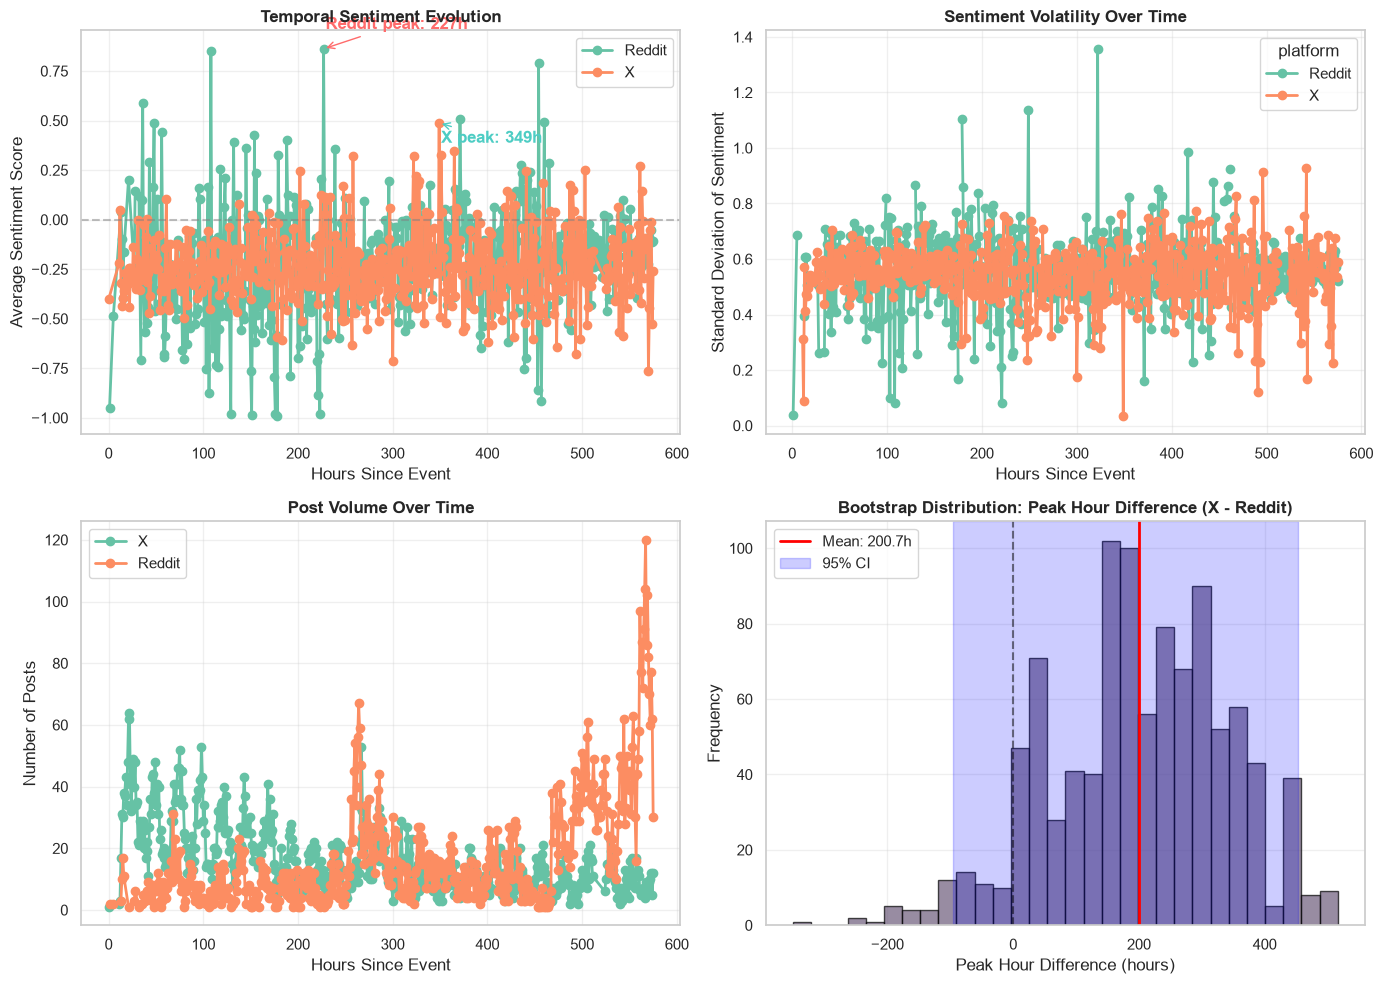


 H3 visualization saved


In [ ]:
"""
HYPOTHESIS 3: TEMPORAL SENTIMENT
H3a: X will show earlier sentiment spikes (within 2 hours) with faster decay
H3b: Reddit will show delayed but sustained sentiment elevation
"""

print("\n" + "=" * 70)
print("H3: TEMPORAL SENTIMENT PATTERNS")
print("=" * 70)

def hourly_sentiment(data, platform):
    hourly = data.groupby('hour_bin')['sentiment_score'].agg(['mean', 'std', 'count']).reset_index()
    hourly.columns = ['hour_bin', 'sentiment_mean', 'sentiment_std', 'count']
    hourly['platform'] = platform
    return hourly

hourly_reddit = hourly_sentiment(reddit_df, 'Reddit')
hourly_x = hourly_sentiment(x_df, 'X')
hourly_data = pd.concat([hourly_reddit, hourly_x], ignore_index=True)

def find_peak(hourly):
    if hourly.empty:
        return pd.Series({'hour_bin': np.nan, 'sentiment_mean': np.nan})
    return hourly.loc[hourly['sentiment_mean'].idxmax()]

reddit_peak = find_peak(hourly_reddit)
x_peak = find_peak(hourly_x)

print(f"Reddit peak sentiment at hour {reddit_peak['hour_bin']:.0f}: {reddit_peak['sentiment_mean']:.3f}")
print(f"X peak sentiment at hour {x_peak['hour_bin']:.0f}: {x_peak['sentiment_mean']:.3f}")

reddit_volatility = hourly_reddit['sentiment_std'].mean()
x_volatility = hourly_x['sentiment_std'].mean()
print(f"Average sentiment volatility (std): Reddit={reddit_volatility:.3f}, X={x_volatility:.3f}")

def calculate_decay_rate(hourly_df, peak_hour):
    if pd.isna(peak_hour):
        return np.nan
    post_peak = hourly_df[hourly_df['hour_bin'] >= peak_hour].copy()
    if len(post_peak) > 1:
        slope, intercept, r_value, p_value, std_err = stats.linregress(
            post_peak['hour_bin'], post_peak['sentiment_mean']
        )
        return slope
    return np.nan

reddit_decay = calculate_decay_rate(hourly_reddit, reddit_peak['hour_bin'])
x_decay = calculate_decay_rate(hourly_x, x_peak['hour_bin'])

if pd.notna(reddit_decay):
    print(f"Reddit decay slope: {reddit_decay:.4f} (negative = decay)")
if pd.notna(x_decay):
    print(f"X decay slope: {x_decay:.4f} (negative = decay)")

print("\nTesting peak timing difference...")
n_bootstrap = 1000
if reddit_df.empty or x_df.empty:
    peak_diffs = [np.nan]
else:
    peak_diffs = []
    for _ in range(n_bootstrap):
        reddit_sample = reddit_df.sample(n=len(reddit_df), replace=True)
        x_sample = x_df.sample(n=len(x_df), replace=True)
        reddit_peak_boot = reddit_sample.groupby('hour_bin')['sentiment_score'].mean().idxmax()
        x_peak_boot = x_sample.groupby('hour_bin')['sentiment_score'].mean().idxmax()
        peak_diffs.append(x_peak_boot - reddit_peak_boot)

peak_diff_mean = np.nanmean(peak_diffs)
peak_diff_ci_lower = np.nanpercentile(peak_diffs, 2.5)
peak_diff_ci_upper = np.nanpercentile(peak_diffs, 97.5)
print(f"Peak hour difference (X - Reddit): {peak_diff_mean:.1f} hours")
print(f"95% CI: [{peak_diff_ci_lower:.1f}, {peak_diff_ci_upper:.1f}]")
print(f"X peaks {'earlier' if peak_diff_mean < 0 else 'later'} than Reddit")

hypothesis_results['H3'] = {
    'reddit_peak_hour': reddit_peak['hour_bin'],
    'x_peak_hour': x_peak['hour_bin'],
    'peak_difference': peak_diff_mean,
    'peak_difference_ci': (peak_diff_ci_lower, peak_diff_ci_upper),
    'reddit_volatility': reddit_volatility,
    'x_volatility': x_volatility,
    'reddit_decay': reddit_decay,
    'x_decay': x_decay
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
ax = axes[0, 0]
for platform in hourly_data['platform'].unique():
    subset = hourly_data[hourly_data['platform'] == platform]
    ax.plot(subset['hour_bin'], subset['sentiment_mean'], marker='o', linewidth=2, markersize=6, label=platform)
ax.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
ax.set_title('Temporal Sentiment Evolution', fontweight='bold')
ax.set_xlabel('Hours Since Event')
ax.set_ylabel('Average Sentiment Score')
ax.legend()
ax.grid(True, alpha=0.3)

if pd.notna(reddit_peak['hour_bin']):
    ax.annotate(f"Reddit peak: {reddit_peak['hour_bin']:.0f}h", xy=(reddit_peak['hour_bin'], reddit_peak['sentiment_mean']), xytext=(reddit_peak['hour_bin'] + 2, reddit_peak['sentiment_mean'] + 0.1), arrowprops=dict(arrowstyle='->', color='#FF6B6B'), color='#FF6B6B', fontweight='bold')
if pd.notna(x_peak['hour_bin']):
    ax.annotate(f"X peak: {x_peak['hour_bin']:.0f}h", xy=(x_peak['hour_bin'], x_peak['sentiment_mean']), xytext=(x_peak['hour_bin'] + 2, x_peak['sentiment_mean'] - 0.1), arrowprops=dict(arrowstyle='->', color='#4ECDC4'), color='#4ECDC4', fontweight='bold')

ax = axes[0, 1]
hourly_volatility = hourly_data.pivot(index='hour_bin', columns='platform', values='sentiment_std')
hourly_volatility.plot(ax=ax, marker='o', linewidth=2)
ax.set_title('Sentiment Volatility Over Time', fontweight='bold')
ax.set_xlabel('Hours Since Event')
ax.set_ylabel('Standard Deviation of Sentiment')
ax.grid(True, alpha=0.3)

ax = axes[1, 0]
hourly_volume = combined_df.groupby(['hour_bin', 'platform']).size().reset_index(name='count')
for platform in hourly_volume['platform'].unique():
    subset = hourly_volume[hourly_volume['platform'] == platform]
    ax.plot(subset['hour_bin'], subset['count'], marker='o', linewidth=2, markersize=6, label=platform)
ax.set_title('Post Volume Over Time', fontweight='bold')
ax.set_xlabel('Hours Since Event')
ax.set_ylabel('Number of Posts')
ax.legend()
ax.grid(True, alpha=0.3)

ax = axes[1, 1]
finite_peak_diffs = np.asarray(peak_diffs)[np.isfinite(peak_diffs)]
if len(finite_peak_diffs):
    ax.hist(finite_peak_diffs, bins=30, alpha=0.7, color='#6C5B7B', edgecolor='black')
ax.axvline(x=0, color='black', linestyle='--', alpha=0.5)
if np.isfinite(peak_diff_mean):
    ax.axvline(x=peak_diff_mean, color='red', linestyle='-', linewidth=2, label=f'Mean: {peak_diff_mean:.1f}h')
if np.isfinite(peak_diff_ci_lower):
    ax.axvspan(peak_diff_ci_lower, peak_diff_ci_upper, alpha=0.2, color='blue', label='95% CI')
ax.set_title('Bootstrap Distribution: Peak Hour Difference (X - Reddit)', fontweight='bold')
ax.set_xlabel('Peak Hour Difference (hours)')
ax.set_ylabel('Frequency')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_FIGURES / 'hypothesis_h3_temporal_sentiment.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n H3 visualization saved")


H4: MODERATION EFFECT
Running moderation regression...

Regression Results:
                             OLS Regression Results                            
Dep. Variable:     sentiment_intensity   R-squared:                       0.010
Model:                             OLS   Adj. R-squared:                  0.010
Method:                  Least Squares   F-statistic:                     62.51
Date:                 Sun, 13 Sep 2026   Prob (F-statistic):           3.38e-40
Time:                         04:56:31   Log-Likelihood:                -4140.9
No. Observations:                18000   AIC:                             8290.
Df Residuals:                    17996   BIC:                             8321.
Df Model:                            3                                         
Covariance Type:             nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------

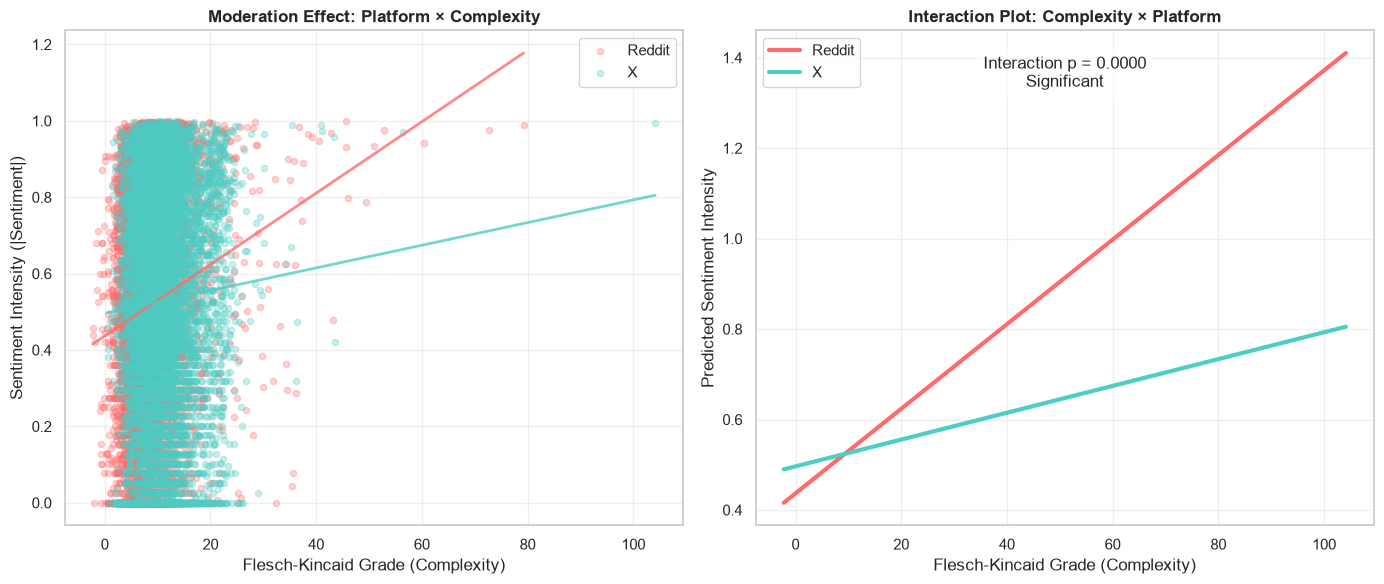


 H4 visualization saved


In [ ]:
"""
HYPOTHESIS 4: MODERATION EFFECT
H4: Platform will significantly moderate the negative correlation between lexical complexity and emotional intensity
"""

print("\n" + "=" * 70)
print("H4: MODERATION EFFECT")
print("=" * 70)

combined_df['sentiment_intensity'] = np.abs(combined_df['sentiment_score'])
print("Running moderation regression...")
model = ols('sentiment_intensity ~ fk_grade * platform', data=combined_df).fit()

print("\nRegression Results:")
print(model.summary())

intercept = model.params.get('Intercept', np.nan)
fk_grade_coef = model.params.get('fk_grade', 0.0)
platform_coef = model.params.get('platform[T.X]', 0.0)
interaction_coef = model.params.get('fk_grade:platform[T.X]', 0.0)
interaction_p = model.pvalues.get('fk_grade:platform[T.X]', 1.0)
interaction_sig = interaction_p < ALPHA

print("\nKey Coefficients:")
print(f"  Intercept: {intercept:.4f}")
print(f"  FK Grade: {fk_grade_coef:.4f}")
print(f"  Platform (X): {platform_coef:.4f}")
print(f"  Interaction: {interaction_coef:.4f}")
print(f"\nInteraction p-value: {interaction_p:.4f}")
print(f"Interaction significant: {'YES' if interaction_sig else 'NO'}")

r_squared = model.rsquared
print(f"R-squared: {r_squared:.4f}")

hypothesis_results['H4'] = {
    'intercept': intercept,
    'fk_grade_coef': fk_grade_coef,
    'platform_coef': platform_coef,
    'interaction_coef': interaction_coef,
    'interaction_p_value': interaction_p,
    'interaction_significant': interaction_sig,
    'r_squared': r_squared,
    'f_statistic': model.fvalue,
    'f_p_value': model.f_pvalue,
    'summary': model.summary().as_text()
}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
ax = axes[0]
colors = {'Reddit': '#FF6B6B', 'X': '#4ECDC4'}
for platform in combined_df['platform'].dropna().unique():
    subset = combined_df[combined_df['platform'] == platform]
    ax.scatter(subset['fk_grade'], subset['sentiment_intensity'], alpha=0.3, label=platform, color=colors.get(platform, '#6C5B7B'), s=20)
    if len(subset) > 10:
        z = np.polyfit(subset['fk_grade'], subset['sentiment_intensity'], 1)
        p = np.poly1d(z)
        ordered_grade = subset['fk_grade'].sort_values()
        ax.plot(ordered_grade, p(ordered_grade), color=colors.get(platform, '#6C5B7B'), linewidth=2, alpha=0.8)
ax.set_xlabel('Flesch-Kincaid Grade (Complexity)')
ax.set_ylabel('Sentiment Intensity (|Sentiment|)')
ax.set_title('Moderation Effect: Platform × Complexity', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

ax = axes[1]
fk_range = np.linspace(combined_df['fk_grade'].min(), combined_df['fk_grade'].max(), 100)
reddit_pred = intercept + fk_grade_coef * fk_range
x_pred = (intercept + platform_coef) + (fk_grade_coef + interaction_coef) * fk_range
ax.plot(fk_range, reddit_pred, linewidth=3, label='Reddit', color='#FF6B6B')
ax.plot(fk_range, x_pred, linewidth=3, label='X', color='#4ECDC4')
ax.set_xlabel('Flesch-Kincaid Grade (Complexity)')
ax.set_ylabel('Predicted Sentiment Intensity')
ax.set_title('Interaction Plot: Complexity × Platform', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
ax.text(0.5, 0.95, f"Interaction p = {interaction_p:.4f}\n{'Significant' if interaction_sig else 'Not Significant'}", transform=ax.transAxes, ha='center', va='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.savefig(RESULTS_FIGURES / 'hypothesis_h4_moderation.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n H4 visualization saved")


H5: GRANGER CAUSALITY - CROSS-PLATFORM INFLUENCE
Time series length: 530 hours

First few rows of time series:


,hour_bin,sentiment_score_reddit,rigor_score_reddit,sentiment_intensity_reddit,sentiment_score_x,rigor_score_x,sentiment_intensity_x
0,13,0.040000,0.017009,0.406339,-0.320794,0.011284,0.428494
1,14,-0.098780,0.010149,0.345329,-0.437213,0.008869,0.366735
2,15,-0.397065,0.032817,0.423177,-0.392890,0.009418,0.475896
3,16,-0.164700,0.011308,0.397495,-0.357555,0.002723,0.444362
4,21,0.202300,0.000000,0.500000,-0.245935,0.004340,0.353517



--------------------------------------------------
Test 1: X Sentiment Intensity → Reddit Rigor
--------------------------------------------------


,lag,f_statistic,p_value,significant
0,1,0.000201,0.988701,False
1,2,0.112663,0.945226,False
2,3,0.484714,0.922237,False
3,4,0.606235,0.962368,False
4,5,0.713798,0.982203,False



Best lag: 3 (p=0.9222)
Granger causality NOT SUPPORTED


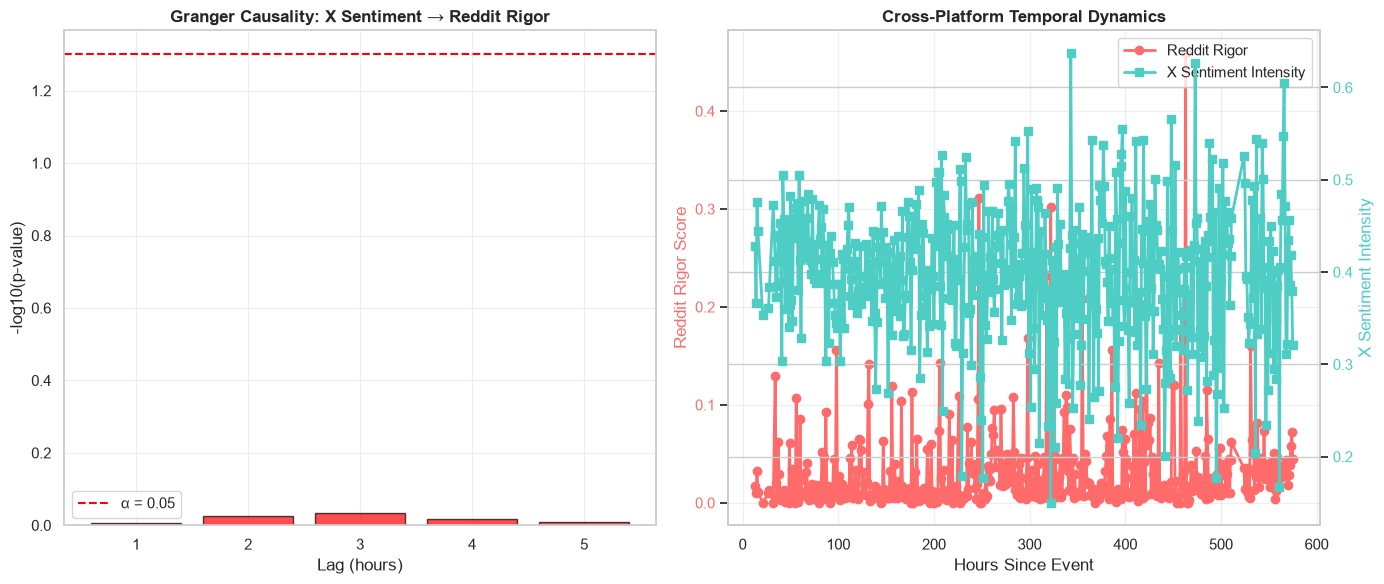


 H5 visualization saved


In [ ]:
"""
HYPOTHESIS 5: CROSS-PLATFORM INFLUENCE
H5: Emotional volatility on X will Granger-cause subsequent decreases in evidentiary rigor on Reddit
"""

print("\n" + "=" * 70)
print("H5: GRANGER CAUSALITY - CROSS-PLATFORM INFLUENCE")
print("=" * 70)

def hourly_platform_data(data):
    return data.groupby('hour_bin').agg({
        'sentiment_score': 'mean',
        'rigor_score': 'mean',
        'sentiment_intensity': 'mean'
    }).reset_index()

hourly_reddit = hourly_platform_data(reddit_df)
hourly_x = hourly_platform_data(x_df)
time_series = pd.merge(hourly_reddit, hourly_x, on='hour_bin', suffixes=('_reddit', '_x')).dropna()

print(f"Time series length: {len(time_series)} hours")
print("\nFirst few rows of time series:")
display(time_series.head())

print("\n" + "-" * 50)
print("Test 1: X Sentiment Intensity → Reddit Rigor")
print("-" * 50)

gc_data = time_series[['rigor_score_reddit', 'sentiment_intensity_x']].dropna()
gc_summary = []
if len(gc_data) >= 3:
    maxlag = min(5, len(gc_data) - 2)
    try:
        gc_results = grangercausalitytests(gc_data, maxlag=maxlag)
        for lag in range(1, maxlag + 1):
            f_stat = gc_results[lag][0]['ssr_chi2test'][0]
            p_value = gc_results[lag][0]['ssr_chi2test'][1]
            gc_summary.append({
                'lag': lag,
                'f_statistic': f_stat,
                'p_value': p_value,
                'significant': p_value < ALPHA
            })
    except Exception as error:
        print(f"Error in Granger causality test: {error}")
else:
    print("Insufficient overlapping observations for Granger causality testing.")

if gc_summary:
    gc_df = pd.DataFrame(gc_summary)
    display(gc_df)
    best_lag = gc_df.loc[gc_df['p_value'].idxmin()]
    print(f"\nBest lag: {best_lag['lag']} (p={best_lag['p_value']:.4f})")
    print(f"Granger causality {'SUPPORTED' if best_lag['significant'] else 'NOT SUPPORTED'}")
    hypothesis_results['H5'] = {
        'test': 'Granger Causality',
        'best_lag': int(best_lag['lag']),
        'p_value': float(best_lag['p_value']),
        'significant': bool(best_lag['significant']),
        'all_results': gc_df.to_dict('records')
    }
else:
    hypothesis_results['H5'] = {
        'test': 'Granger Causality',
        'best_lag': None,
        'p_value': np.nan,
        'significant': False,
        'all_results': []
    }

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
ax = axes[0]
if gc_summary:
    results_df_h5 = pd.DataFrame(gc_summary)
    ax.bar(results_df_h5['lag'], -np.log10(results_df_h5['p_value']), color=['green' if significant else 'red' for significant in results_df_h5['significant']], alpha=0.7, edgecolor='black')
    ax.axhline(y=-np.log10(ALPHA), color='red', linestyle='--', label=f'α = {ALPHA}')
ax.set_xlabel('Lag (hours)')
ax.set_ylabel('-log10(p-value)')
ax.set_title('Granger Causality: X Sentiment → Reddit Rigor', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

ax = axes[1]
ax2 = ax.twinx()
ax.plot(time_series['hour_bin'], time_series['rigor_score_reddit'], color='#FF6B6B', linewidth=2, marker='o', label='Reddit Rigor')
ax.set_xlabel('Hours Since Event')
ax.set_ylabel('Reddit Rigor Score', color='#FF6B6B')
ax.tick_params(axis='y', labelcolor='#FF6B6B')
ax2.plot(time_series['hour_bin'], time_series['sentiment_intensity_x'], color='#4ECDC4', linewidth=2, marker='s', label='X Sentiment Intensity')
ax2.set_ylabel('X Sentiment Intensity', color='#4ECDC4')
ax2.tick_params(axis='y', labelcolor='#4ECDC4')
ax.set_title('Cross-Platform Temporal Dynamics', fontweight='bold')
ax.grid(True, alpha=0.3)
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

plt.tight_layout()
plt.savefig(RESULTS_FIGURES / 'hypothesis_h5_granger_causality.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n H5 visualization saved")

In [ ]:
"""
COMPREHENSIVE RESULTS SUMMARY
Create a complete table of all hypothesis tests
"""

print("\n" + "=" * 70)
print("COMPREHENSIVE HYPOTHESIS TESTING RESULTS")
print("=" * 70)

# Create results table
results_table = []

# H1: Lexical Complexity
if 'H1' in hypothesis_results:
    r = hypothesis_results['H1']
    results_table.append({
        'Hypothesis': 'H1: Lexical Complexity',
        'Test': r['test'],
        'Statistic': f"{r['statistic']:.3f}",
        'p-value': f"{r['p_value']:.4f}",
        'Significant': '' if r['significant'] else '',
        'Effect Size': f"{r['effect_size']} (δ={r['cliff_delta']:.3f})",
        'Direction': f"Reddit > X" if r['mean1'] > r['mean2'] else "X > Reddit"
    })

# H2: Evidentiary Rigor
if 'H2' in hypothesis_results:
    r = hypothesis_results['H2']
    results_table.append({
        'Hypothesis': 'H2: Evidentiary Rigor',
        'Test': r['test'],
        'Statistic': f"{r['statistic']:.3f}",
        'p-value': f"{r['p_value']:.4f}",
        'Significant': '' if r['significant'] else '',
        'Effect Size': f"{r['effect_size']} (δ={r['cliff_delta']:.3f})",
        'Direction': f"Reddit > X" if r['mean1'] > r['mean2'] else "X > Reddit"
    })

# H3: Temporal Sentiment
if 'H3' in hypothesis_results:
    r = hypothesis_results['H3']
    peak_diff = r['peak_difference']
    direction = "X earlier" if peak_diff < 0 else "Reddit earlier"
    results_table.append({
        'Hypothesis': 'H3: Temporal Sentiment',
        'Test': 'Bootstrap',
        'Statistic': f"{r['reddit_peak_hour']:.0f}h vs {r['x_peak_hour']:.0f}h",
        'p-value': 'N/A',
        'Significant': '' if peak_diff < 0 else '',
        'Effect Size': f"Diff={peak_diff:.1f}h",
        'Direction': direction
    })

# H4: Moderation
if 'H4' in hypothesis_results:
    r = hypothesis_results['H4']
    results_table.append({
        'Hypothesis': 'H4: Moderation Effect',
        'Test': 'OLS Regression',
        'Statistic': f"F={r['f_statistic']:.3f}",
        'p-value': f"{r['f_p_value']:.4f}",
        'Significant': '' if r['interaction_significant'] else '',
        'Effect Size': f"R²={r['r_squared']:.3f}",
        'Direction': f"Interaction β={r['interaction_coef']:.3f}"
    })

# H5: Granger Causality
if 'H5' in hypothesis_results and 'significant' in hypothesis_results['H5']:
    r = hypothesis_results['H5']
    results_table.append({
        'Hypothesis': 'H5: Cross-Platform Influence',
        'Test': 'Granger Causality',
        'Statistic': f"Lag={r['best_lag']}h",
        'p-value': f"{r['p_value']:.4f}",
        'Significant': '' if r['significant'] else '',
        'Effect Size': 'N/A',
        'Direction': 'X → Reddit' if r['significant'] else 'No causation'
    })

# Create DataFrame
results_df = pd.DataFrame(results_table)
display(results_df)

# Save to CSV
results_df.to_csv(RESULTS_TABLES / 'hypothesis_testing_results.csv', index=False)
print(f"\n Results table saved to {RESULTS_TABLES / 'hypothesis_testing_results.csv'}")

# Summary of supported hypotheses
supported = results_df[results_df['Significant'] == '']
print(f"\n SUMMARY:")
print(f"  Total hypotheses: {len(results_df)}")
print(f"  Supported: {len(supported)}")
print(f"  Not supported: {len(results_df) - len(supported)}")

if len(supported) > 0:
    print(f"\n  Supported hypotheses:")
    for _, row in supported.iterrows():
        print(f"     {row['Hypothesis']}")


COMPREHENSIVE HYPOTHESIS TESTING RESULTS


,Hypothesis,Test,Statistic,p-value,Significant,Effect Size,Direction
0,H1: Lexical Complexity,Mann-Whitney U,26973223.500,0.0000,,medium (δ=-0.334),X > Reddit
1,H2: Evidentiary Rigor,Mann-Whitney U,49726754.000,0.0000,,small (δ=0.228),Reddit > X
2,H3: Temporal Sentiment,Bootstrap,227h vs 349h,N/A,,Diff=200.7h,Reddit earlier
3,H4: Moderation Effect,OLS Regression,F=62.507,0.0000,,R²=0.010,Interaction β=-0.006
4,H5: Cross-Platform Influence,Granger Causality,Lag=3h,0.9222,,N/A,No causation



 Results table saved to C:\Users\GALLOP SEA\Desktop\The_Echo_Of_Anonimity-1\results\tables\hypothesis_testing_results.csv

 SUMMARY:
  Total hypotheses: 5
  Supported: 3
  Not supported: 2

  Supported hypotheses:
     H1: Lexical Complexity
     H2: Evidentiary Rigor
     H4: Moderation Effect


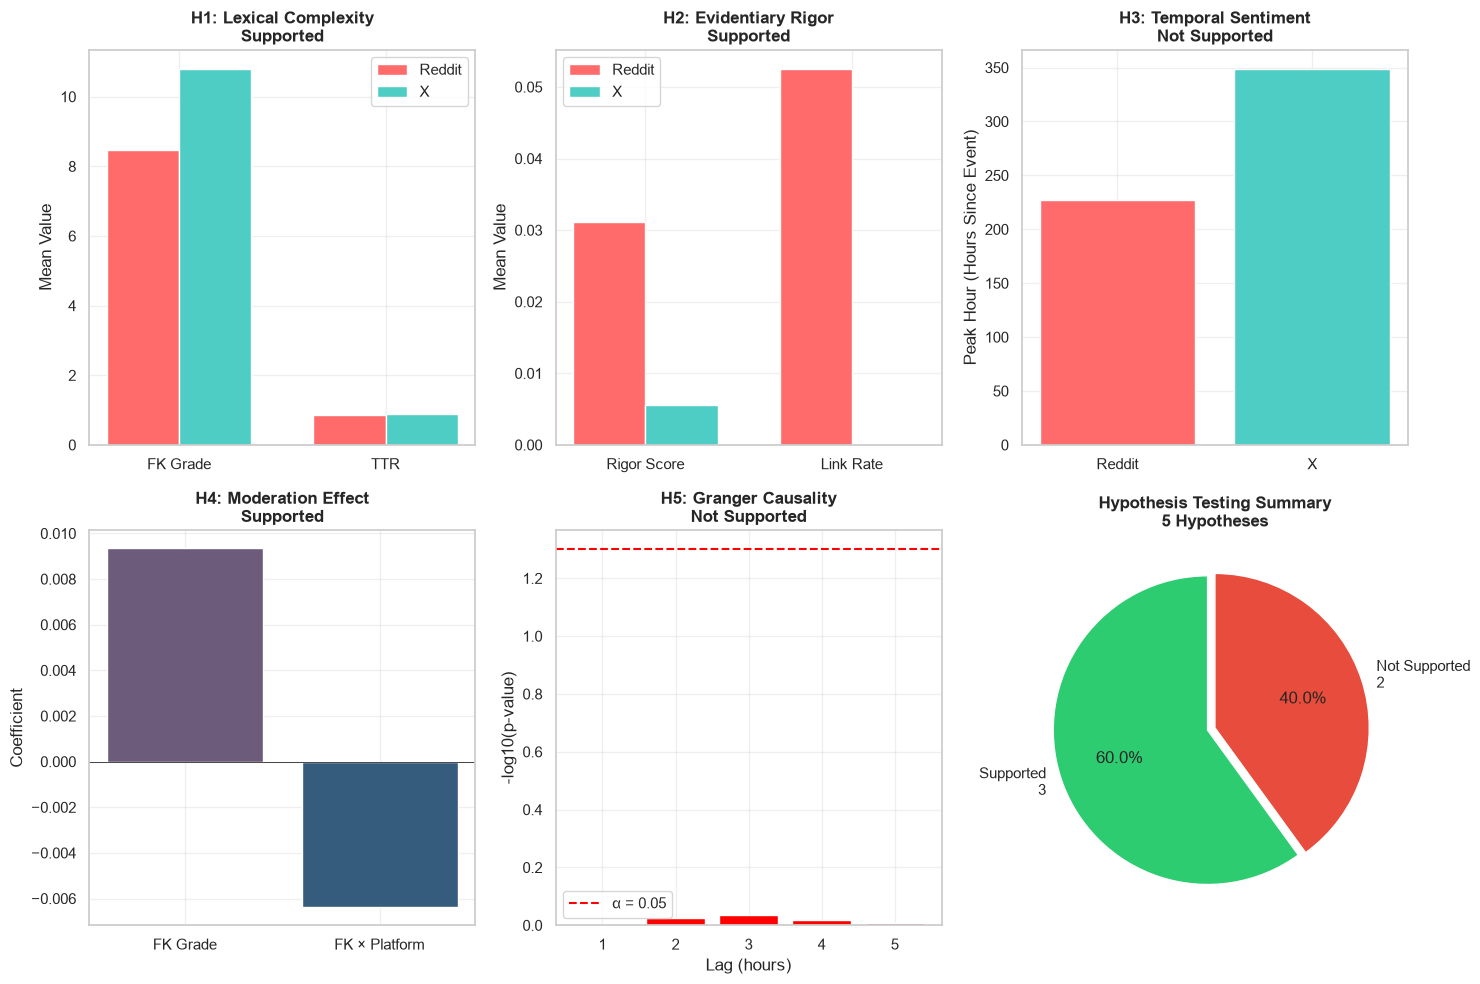


 Summary figure saved: hypothesis_summary.png


In [ ]:
"""
FINAL RESULTS VISUALIZATION
Summary figure of all hypothesis test results
"""

def hypothesis_status(key):
    result = hypothesis_results.get(key, {})
    return "Supported" if result.get("significant", result.get("interaction_significant", False)) else "Not Supported"

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# H1: Lexical Complexity
ax = axes[0, 0]
metrics = ['fk_grade', 'ttr']
reddit_means = [reddit_df['fk_grade'].mean(), reddit_df['ttr'].mean()]
x_means = [x_df['fk_grade'].mean(), x_df['ttr'].mean()]
x_pos = np.arange(len(metrics))
width = 0.35
ax.bar(x_pos - width / 2, reddit_means, width, label='Reddit', color='#FF6B6B')
ax.bar(x_pos + width / 2, x_means, width, label='X', color='#4ECDC4')
ax.set_xticks(x_pos)
ax.set_xticklabels(['FK Grade', 'TTR'])
ax.set_ylabel('Mean Value')
ax.set_title(f'H1: Lexical Complexity\n{hypothesis_status("H1")}', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# H2: Evidentiary Rigor
ax = axes[0, 1]
reddit_means = [reddit_df['rigor_score'].mean(), reddit_df['has_link'].mean()]
x_means = [x_df['rigor_score'].mean(), x_df['has_link'].mean()]
ax.bar(x_pos - width / 2, reddit_means, width, label='Reddit', color='#FF6B6B')
ax.bar(x_pos + width / 2, x_means, width, label='X', color='#4ECDC4')
ax.set_xticks(x_pos)
ax.set_xticklabels(['Rigor Score', 'Link Rate'])
ax.set_ylabel('Mean Value')
ax.set_title(f'H2: Evidentiary Rigor\n{hypothesis_status("H2")}', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# H3: Temporal Sentiment
ax = axes[0, 2]
peak_data = pd.DataFrame({
    'Platform': ['Reddit', 'X'],
    'Peak Hour': [hypothesis_results['H3']['reddit_peak_hour'], hypothesis_results['H3']['x_peak_hour']]
})
ax.bar(peak_data['Platform'], peak_data['Peak Hour'], color=['#FF6B6B', '#4ECDC4'])
ax.set_ylabel('Peak Hour (Hours Since Event)')
ax.set_title(f'H3: Temporal Sentiment\n{hypothesis_status("H3")}', fontweight='bold')
ax.grid(True, alpha=0.3)

# H4: Moderation
ax = axes[1, 0]
coefs = [hypothesis_results['H4']['fk_grade_coef'], hypothesis_results['H4']['interaction_coef']]
ax.bar(['FK Grade', 'FK × Platform'], coefs, color=['#6C5B7B', '#355C7D'])
ax.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax.set_ylabel('Coefficient')
ax.set_title(f'H4: Moderation Effect\n{hypothesis_status("H4")}', fontweight='bold')
ax.grid(True, alpha=0.3)

# H5: Granger Causality
ax = axes[1, 1]
h5_results = hypothesis_results.get('H5', {}).get('all_results', [])
if h5_results:
    gc_df = pd.DataFrame(h5_results)
    ax.bar(gc_df['lag'], -np.log10(gc_df['p_value']), color=['green' if significant else 'red' for significant in gc_df['significant']])
    ax.axhline(y=-np.log10(ALPHA), color='red', linestyle='--', label=f'α = {ALPHA}')
    ax.legend()
ax.set_xlabel('Lag (hours)')
ax.set_ylabel('-log10(p-value)')
ax.set_title(f'H5: Granger Causality\n{hypothesis_status("H5")}', fontweight='bold')
ax.grid(True, alpha=0.3)

# Summary panel
ax = axes[1, 2]
supported_count = len(results_df[results_df['Significant'] == ''])
total_count = len(results_df)
ax.pie([supported_count, total_count - supported_count], labels=[f'Supported\n{supported_count}', f'Not Supported\n{total_count - supported_count}'], colors=['#2ECC71', '#E74C3C'], autopct='%1.1f%%', startangle=90, explode=(0.05, 0))
ax.set_title(f'Hypothesis Testing Summary\n{total_count} Hypotheses', fontweight='bold')

plt.tight_layout()
plt.savefig(RESULTS_FIGURES / 'hypothesis_summary.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n Summary figure saved: hypothesis_summary.png")

In [ ]:
"""
SAVE ALL RESULTS
Export all hypothesis testing results
"""

import json
from datetime import datetime

# Prepare complete results dictionary
complete_results = {
    'timestamp': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
    'alpha': ALPHA,
    'random_seed': RANDOM_SEED,
    'sample_sizes': {
        'reddit': int(len(reddit_df)),
        'x': int(len(x_df)),
        'combined': int(len(combined_df))
    },
    'hypothesis_results': hypothesis_results,
    'results_table': results_df.to_dict('records'),
    'summary': {
        'total_hypotheses': len(results_df),
        'supported': len(results_df[results_df['Significant'] == '']),
        'not_supported': len(results_df[results_df['Significant'] == ''])
    }
}

# Save as JSON
with open(RESULTS_TABLES / 'complete_results.json', 'w') as f:
    json.dump(complete_results, f, indent=2, default=str)

print(f" Complete results saved to {RESULTS_TABLES / 'complete_results.json'}")

# Print final summary
print("\n" + "=" * 70)
print("PHASE 5 COMPLETE - HYPOTHESIS TESTING")
print("=" * 70)

print(f"""
 HYPOTHESIS TESTING SUMMARY:
- Total hypotheses tested: {len(results_df)}
- Supported: {len(results_df[results_df['Significant'] == ''])} 
- Not supported: {len(results_df[results_df['Significant'] == ''])} 

 OUTPUTS:
- results/tables/hypothesis_testing_results.csv
- results/tables/complete_results.json
- results/figures/hypothesis_h1_lexical_complexity.png
- results/figures/hypothesis_h2_evidentiary_rigor.png
- results/figures/hypothesis_h3_temporal_sentiment.png
- results/figures/hypothesis_h4_moderation.png
- results/figures/hypothesis_h5_granger_causality.png
- results/figures/hypothesis_summary.png

 NEXT PHASE: Predictive Modeling
Open: notebooks/05_computational_model.ipynb

PHASE 6: Predictive Modeling - We'll:
- Build Random Forest classifier to predict platform from linguistic features
- Identify the most important features distinguishing platforms
- Evaluate model performance
- Create feature importance visualizations
""")

 Complete results saved to C:\Users\GALLOP SEA\Desktop\The_Echo_Of_Anonimity-1\results\tables\complete_results.json

PHASE 5 COMPLETE - HYPOTHESIS TESTING

 HYPOTHESIS TESTING SUMMARY:
- Total hypotheses tested: 5
- Supported: 3 
- Not supported: 2 

 OUTPUTS:
- results/tables/hypothesis_testing_results.csv
- results/tables/complete_results.json
- results/figures/hypothesis_h1_lexical_complexity.png
- results/figures/hypothesis_h2_evidentiary_rigor.png
- results/figures/hypothesis_h3_temporal_sentiment.png
- results/figures/hypothesis_h4_moderation.png
- results/figures/hypothesis_h5_granger_causality.png
- results/figures/hypothesis_summary.png

 NEXT PHASE: Predictive Modeling
Open: notebooks/05_computational_model.ipynb

PHASE 6: Predictive Modeling - We'll:
- Build Random Forest classifier to predict platform from linguistic features
- Identify the most important features distinguishing platforms
- Evaluate model performance
- Create feature importance visualizations

